# Appendix B: Model Evaluation Metrics in Medicine

This notebook collects the runnable examples of *Appendix B: Model Evaluation Metrics in Medicine* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.


In [1]:
%matplotlib inline

## Example B.1: Computing the main metrics from the confusion matrix

Script version: `example_B_1.py`

In [2]:
# Example B.1: The confusion matrix and the sensitivity, specificity, precision, and F1 metrics
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
 
# 1 = disease, 0 = healthy (a small screening example)
y_true = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0])
 
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f"TP={tp}, FN={fn}, FP={fp}, TN={tn}")
print("Accuracy   :", accuracy_score(y_true, y_pred))
print("Sensitivity:", recall_score(y_true, y_pred), "(= TP / (TP + FN))")
print("Specificity:", round(tn / (tn + fp), 3), "(= TN / (TN + FP))")
print("Precision  :", round(precision_score(y_true, y_pred), 3), "(= TP / (TP + FP))")
print("F1 score   :", round(f1_score(y_true, y_pred), 3))
always_healthy = np.zeros_like(y_true)
print("A model that always says 'healthy' -> accuracy:", accuracy_score(y_true, always_healthy),
      "| sensitivity:", recall_score(y_true, always_healthy))

TP=4, FN=1, FP=2, TN=13
Accuracy   : 0.85
Sensitivity: 0.8 (= TP / (TP + FN))
Specificity: 0.867 (= TN / (TN + FP))
Precision  : 0.667 (= TP / (TP + FP))
F1 score   : 0.727
A model that always says 'healthy' -> accuracy: 0.75 | sensitivity: 0.0


## Example B.2: The ROC curve and the effect of the threshold on sensitivity and specificity

Script version: `example_B_2.py`

AUC = 0.9908
threshold 0.5: sensitivity = 0.938, specificity = 0.991
threshold 0.3: sensitivity = 0.953, specificity = 0.879
threshold 0.1: sensitivity = 1.000, specificity = 0.682


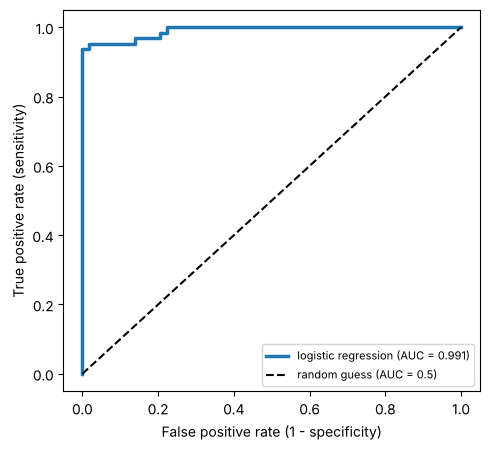

In [3]:
# Example B.2: The ROC curve, the area under the curve (AUC), and choosing a threshold
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, recall_score
 
X, y = load_breast_cancer(return_X_y=True)
y = 1 - y                                  # make 1 = malignant (the "positive" disease class)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=1000)).fit(X_tr, y_tr)
p = model.predict_proba(X_te)[:, 1]
 
fpr, tpr, thr = roc_curve(y_te, p)
print("AUC =", round(roc_auc_score(y_te, p), 4))
for t in (0.5, 0.3, 0.1):
    pred = (p >= t).astype(int)
    spec = np.mean(pred[y_te == 0] == 0)
    print(f"threshold {t}: sensitivity = {recall_score(y_te, pred):.3f}, specificity = {spec:.3f}")
 
plt.figure(figsize=(5, 4.6))
plt.plot(fpr, tpr, lw=2.5, label=f"logistic regression (AUC = {roc_auc_score(y_te, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC = 0.5)")
plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (sensitivity)")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.savefig("figB_1.png", dpi=300)

## Example B.3: Regression evaluation metrics

Script version: `example_B_3.py`

In [4]:
# Example B.3: Regression evaluation metrics — MAE, MSE, RMSE, and R²
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
 
y_true = np.array([120, 135, 128, 150, 142, 118, 160])     # measured systolic BP
y_pred = np.array([118, 130, 131, 155, 138, 121, 150])     # model predictions
mse = mean_squared_error(y_true, y_pred)
print("MAE  =", round(mean_absolute_error(y_true, y_pred), 2), "mmHg")
print("MSE  =", round(mse, 2), "mmHg²")
print("RMSE =", round(np.sqrt(mse), 2), "mmHg")
print("R²   =", round(r2_score(y_true, y_pred), 3))
print("R² of always predicting the mean =", r2_score(y_true, np.full_like(y_true, y_true.mean(), dtype=float)))

MAE  = 4.57 mmHg
MSE  = 26.86 mmHg²
RMSE = 5.18 mmHg
R²   = 0.871
R² of always predicting the mean = 0.0


## Example B.4: The effect of class weighting on data with a prevalence of 3 percent

Script version: `example_B_4.py`

In [5]:
# Example B.4: Imbalanced data — the effect of class weighting
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, balanced_accuracy_score, accuracy_score
 
X, y = make_classification(n_samples=5000, n_features=10, n_informative=4, weights=[0.97, 0.03],
                           class_sep=0.8, random_state=3)
print("Positive (disease) share:", round(y.mean(), 3))
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
for cw in (None, "balanced"):
    m = LogisticRegression(class_weight=cw, max_iter=1000).fit(X_tr, y_tr)
    pr = m.predict(X_te)
    print(f"class_weight={str(cw):<9} accuracy={accuracy_score(y_te, pr):.3f}  "
          f"sensitivity={recall_score(y_te, pr):.3f}  precision={precision_score(y_te, pr):.3f}  "
          f"balanced acc={balanced_accuracy_score(y_te, pr):.3f}")

Positive (disease) share: 0.033
class_weight=None      accuracy=0.971  sensitivity=0.120  precision=1.000  balanced acc=0.560
class_weight=balanced  accuracy=0.732  sensitivity=0.820  precision=0.094  balanced acc=0.774
